# 03 · Exploratory Data Analysis of RFM Metrics and Segments

**Project:** Olist E-Commerce Customer Segmentation & Retention Analysis  
## Purpose
Explores the validated RFM table (93,358 customers) to understand how recently, how often and how much customers buy, and how the 8 RFM segments differ from one another.

| | |
|---|---|
| **Input** | `customer_rfm_segments_clean.csv` (from Notebook 02) |
| **Output** | Charts and findings (no files are written) |
| **Libraries** | pandas, numpy, matplotlib, seaborn |
| **Environment** | Google Colab |

> **How to run:** execute the cells in order and upload `customer_rfm_segments_clean.csv` when prompted.

**Metric definitions**
- **Recency:** days since the customer's last delivered order (lower = more recent).
- **Frequency:** number of delivered orders.
- **Monetary:** total product spending in Brazilian reais (R$).

## 1. Load the Cleaned RFM Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

rfm_df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", rfm_df.shape)

Saving customer_rfm_segments_clean.csv to customer_rfm_segments_clean.csv
Dataset loaded successfully!
Shape: (93358, 10)


## 2. Distribution of RFM Metrics

In [2]:
# Descriptive statistics of RFM metrics

rfm_df[["recency_days", "frequency", "monetary"]].describe().round(2)

,recency_days,frequency,monetary
count,93358.00,93358.00,93358.00
mean,237.48,1.03,141.62
std,152.60,0.21,215.69
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.73
75%,346.00,1.00,154.74
max,713.00,15.00,13440.00


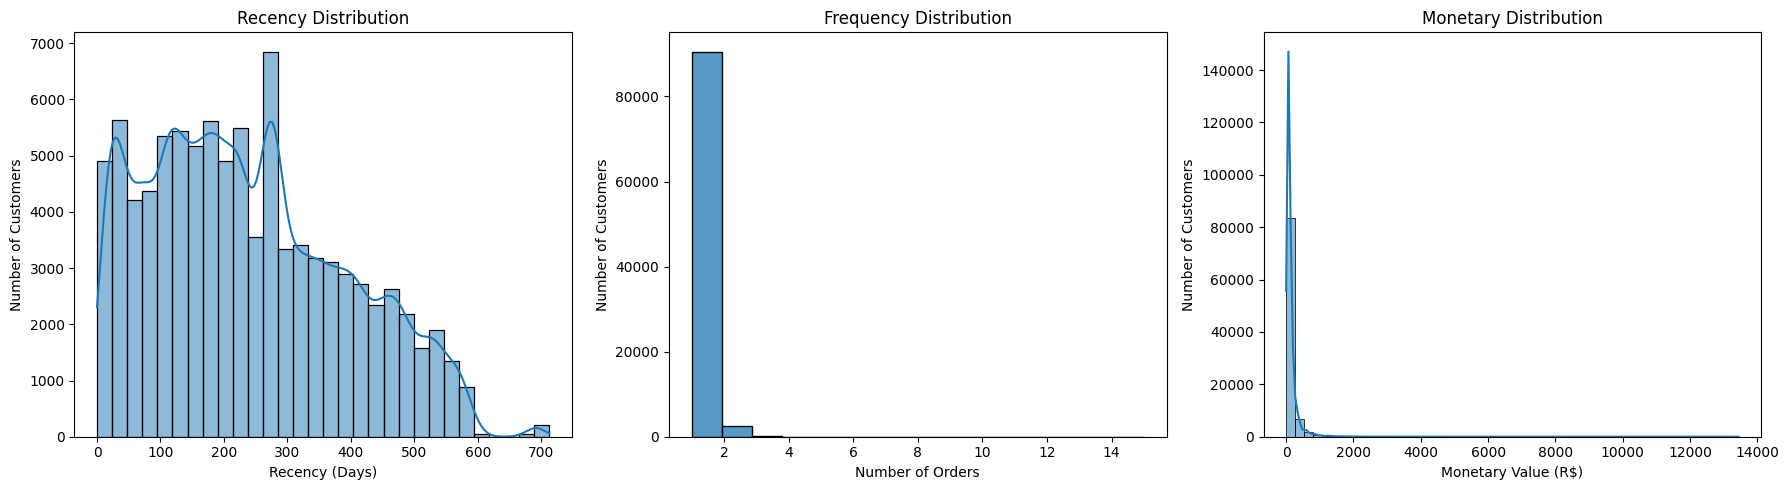

In [3]:
# Distribution of RFM metrics

plt.figure(figsize=(18, 5))

# Recency distribution
plt.subplot(1, 3, 1)
sns.histplot(rfm_df["recency_days"], bins=30, kde=True)
plt.title("Recency Distribution")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")

# Frequency distribution
plt.subplot(1, 3, 2)
sns.histplot(rfm_df["frequency"], bins=15, kde=False)
plt.title("Frequency Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

# Monetary distribution
plt.subplot(1, 3, 3)
sns.histplot(rfm_df["monetary"], bins=50, kde=True)
plt.title("Monetary Distribution")
plt.xlabel("Monetary Value (R$)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [4]:
# Additional distribution analysis

for col in ["recency_days", "frequency", "monetary"]:
    print(f"\n{col.upper()}")
    print("Skewness:", round(rfm_df[col].skew(), 2))
    print("Kurtosis:", round(rfm_df[col].kurtosis(), 2))


RECENCY_DAYS
Skewness: 0.45
Kurtosis: -0.66

FREQUENCY
Skewness: 11.1
Kurtosis: 323.55

MONETARY
Skewness: 9.75
Kurtosis: 265.21


#### Findings: RFM distribution analysis

**Recency**
- Average recency: 237.48 days.
- Median recency: 218 days.
- Skewness: 0.45.
- The distribution is slightly right-skewed, indicating a relatively broad spread of customer purchase recency.

**Frequency**
- Average frequency: 1.03 orders.
- Median frequency: 1 order.
- Skewness: 11.10.
- The distribution is extremely right-skewed, indicating that most customers have one observed delivered order, while a small number purchase repeatedly.

**Monetary**
- Average monetary value: R$141.62.
- Median monetary value: R$89.73.
- Skewness: 9.75.
- The distribution is extremely right-skewed, indicating that a small group of high-spending customers influences the overall average.

**Business Implication:** Customer purchasing behaviour is highly uneven. Retention strategies should consider both the large population of customers with one observed purchase and the smaller group of repeat and high-spending customers.

## 3. Outliers and High-Spending Customers

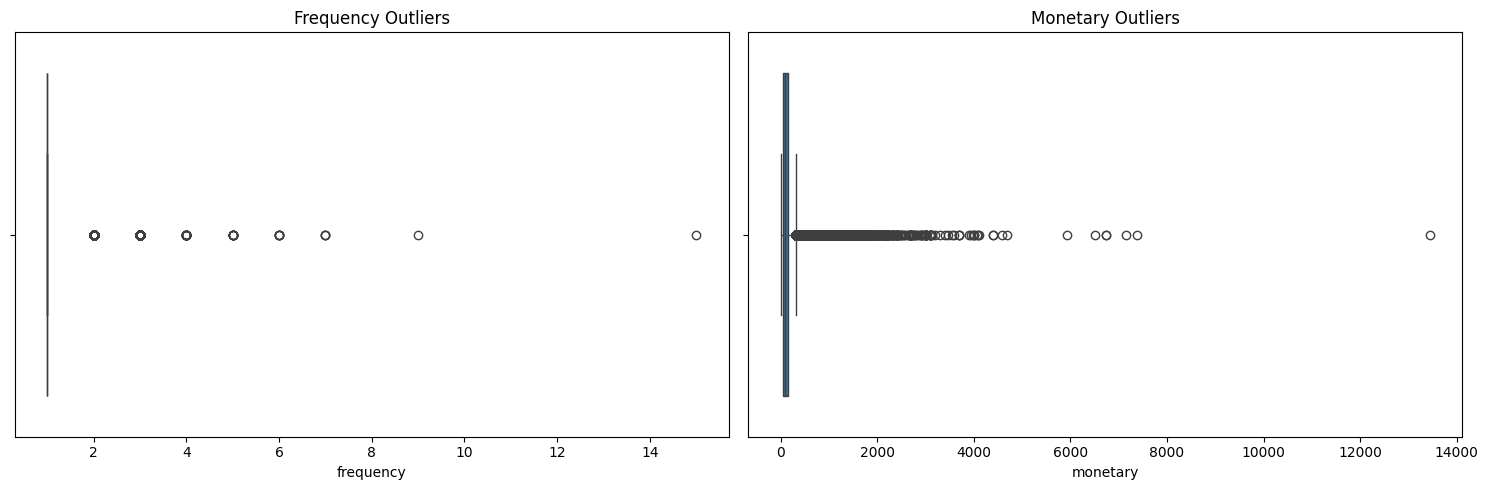

In [5]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=rfm_df["frequency"])
plt.title("Frequency Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(x=rfm_df["monetary"])
plt.title("Monetary Outliers")

plt.tight_layout()
plt.show()

In [6]:
# IQR-based outlier detection

for col in ["frequency", "monetary"]:

    Q1 = rfm_df[col].quantile(0.25)
    Q3 = rfm_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = rfm_df[
        (rfm_df[col] < lower_limit) |
        (rfm_df[col] > upper_limit)
    ]

    print(f"\n{col.upper()}")
    print("Q1:", round(Q1, 2))
    print("Q3:", round(Q3, 2))
    print("IQR:", round(IQR, 2))
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Potential outliers:", len(outliers))
    print("Outlier percentage:",
          round(len(outliers) / len(rfm_df) * 100, 2), "%")


FREQUENCY
Q1: 1.0
Q3: 1.0
IQR: 0.0
Lower limit: 1.0
Upper limit: 1.0
Potential outliers: 2801
Outlier percentage: 3.0 %

MONETARY
Q1: 47.65
Q3: 154.74
IQR: 107.09
Lower limit: -112.98
Upper limit: 315.37
Potential outliers: 7765
Outlier percentage: 8.32 %


In [7]:
# Monetary value distribution among customers

print("MONETARY PERCENTILES")

print(
    rfm_df["monetary"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00])
)

print("\nTOP 10 HIGH-SPENDING CUSTOMERS")

rfm_df[
    ["customer_unique_id", "frequency", "monetary", "customer_segment"]
].sort_values(
    by="monetary",
    ascending=False
).head(10)

MONETARY PERCENTILES
0.500       89.7300
0.750      154.7375
0.900      279.9900
0.950      419.8090
0.990     1004.9900
0.995     1380.0000
1.000    13440.0000
Name: monetary, dtype: float64

TOP 10 HIGH-SPENDING CUSTOMERS


,customer_unique_id,frequency,monetary,customer_segment
3724,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,Big Spenders
79636,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,Big Spenders
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,Recent Customers
80463,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,Big Spenders
25436,459bef486812aa25204be022145caa62,1,6729.0,Recent Customers
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,Big Spenders
23411,4007669dec559734d6f53e029e360987,1,5934.6,Big Spenders
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,Big Spenders
26640,48e1ac109decbb87765a3eade6854098,1,4590.0,Recent Customers
59163,a229eba70ec1c2abef51f04987deb7a5,1,4400.0,Recent Customers


#### Findings: Outliers and spending concentration
- **Frequency:** Q1 and Q3 are both 1, so the IQR is 0 and every customer with more than one order is flagged as an outlier (2,801 customers, 3.0%). The IQR rule is therefore not informative for frequency.
- **Monetary:** the upper fence is R$315.37, which flags 7,765 customers (8.32%).
- Spending is concentrated in a small tail: median R$89.73, 95th percentile R$419.81, 99th percentile R$1,004.99 and a maximum of R$13,440. The top spender made a single order and belongs to *Big Spenders*.

## 4. RFM Profile of Each Customer Segment

In [8]:
# RFM metrics grouped by customer segment

segment_rfm_analysis = (
    rfm_df.groupby("customer_segment")
    .agg(
        customer_count=("customer_unique_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median")
    )
    .round(2)
    .sort_values("avg_monetary", ascending=False)
)

segment_rfm_analysis

,customer_count,avg_recency,avg_frequency,avg_monetary,median_monetary
customer_segment,,,,,
Big Spenders,527,349.27,1.05,1601.47,1350.00
Champions,9,72.22,6.78,805.59,687.76
Loyal Customers,184,158.46,3.28,444.85,334.25
At Risk,490,453.19,2.08,210.07,159.35
Potential Loyalists,20197,133.98,1.06,147.51,94.45
Recent Customers,17904,44.53,1.00,138.57,85.93
Needs Nurturing,34039,263.26,1.03,125.64,88.00
Hibernating,20008,463.32,1.00,122.37,82.28


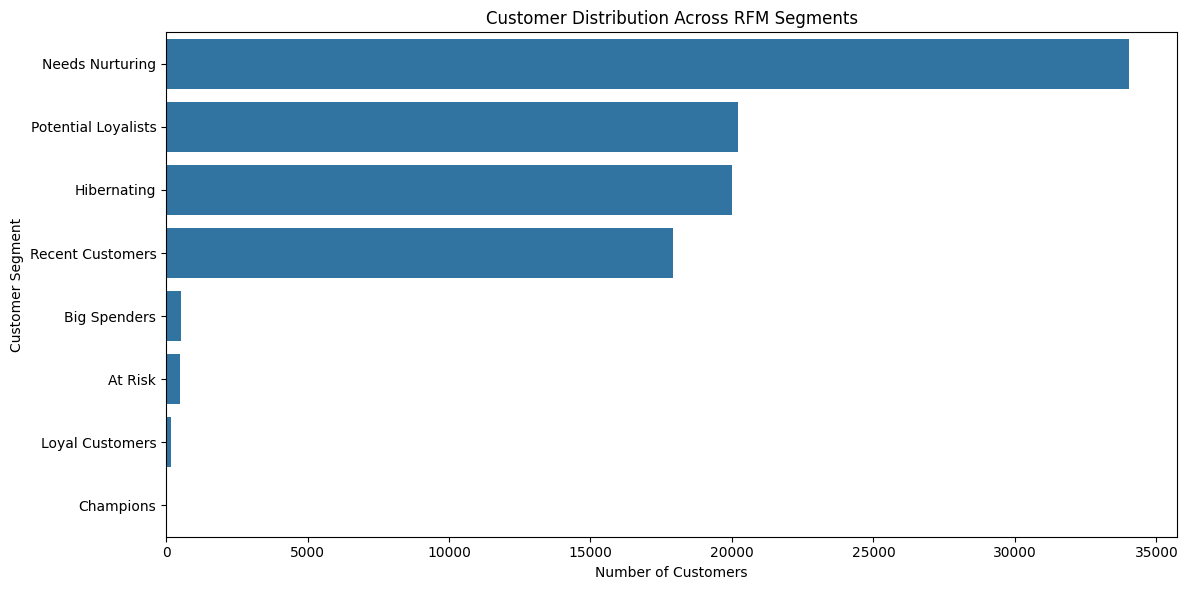

In [9]:
# Customer segment distribution

segment_counts = rfm_df["customer_segment"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index
)

plt.title("Customer Distribution Across RFM Segments")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

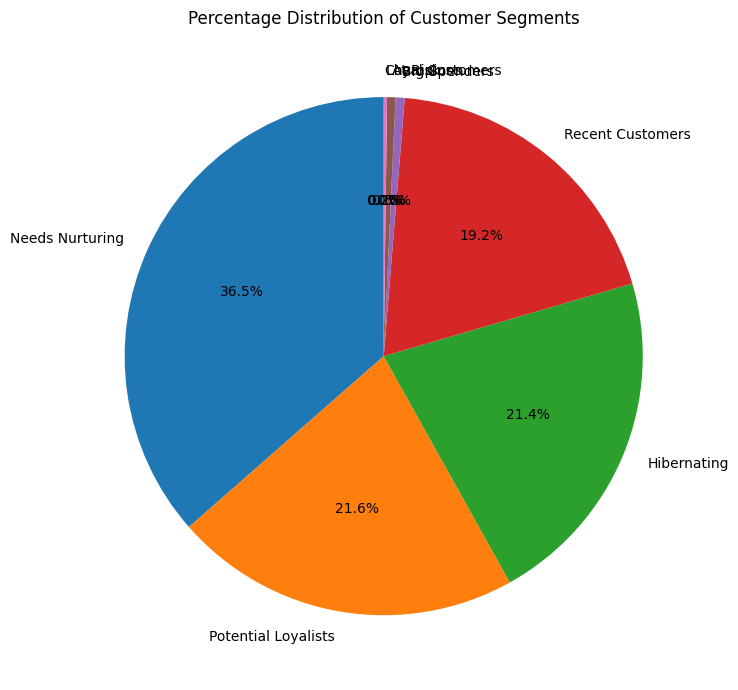

In [10]:
# Customer segment percentage distribution

segment_percentage = (
    rfm_df["customer_segment"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))

plt.pie(
    segment_percentage,
    labels=segment_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Customer Segments")
plt.tight_layout()
plt.show()

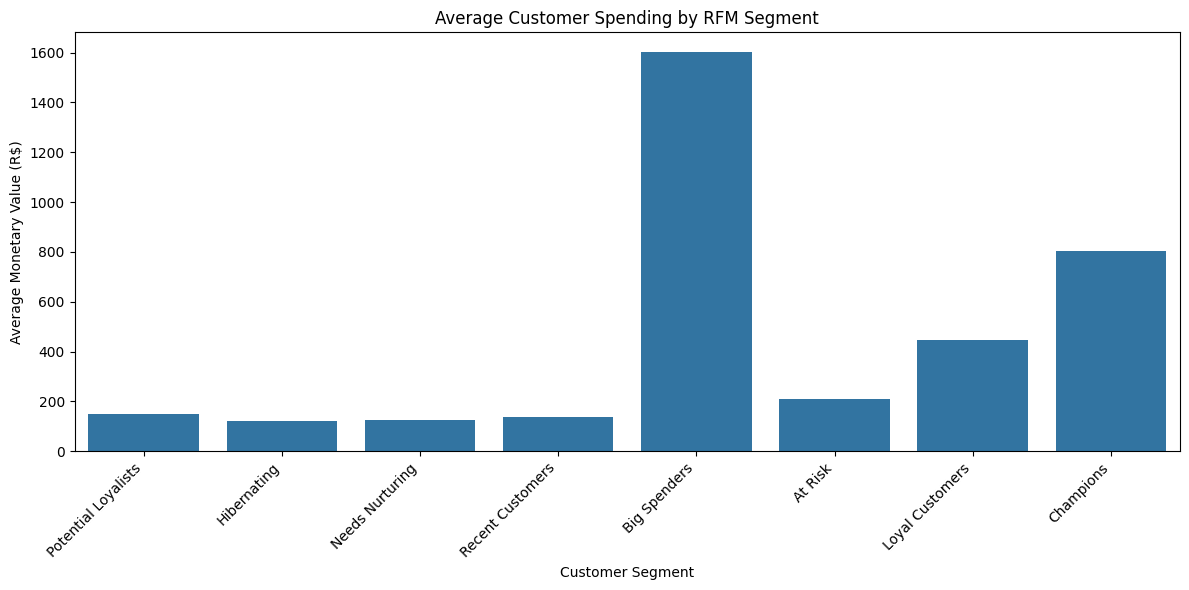

In [11]:
# Average monetary value by customer segment

plt.figure(figsize=(12, 6))

sns.barplot(
    data=rfm_df,
    x="customer_segment",
    y="monetary",
    estimator="mean",
    errorbar=None
)

plt.title("Average Customer Spending by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Monetary Value (R$)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

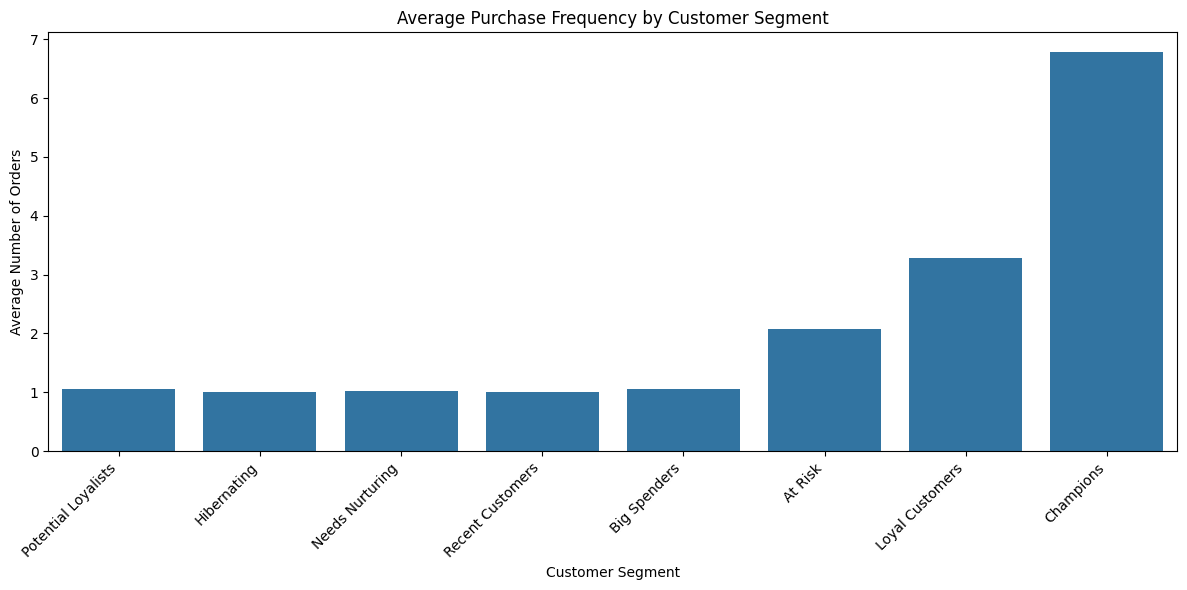

In [12]:
# Average purchase frequency by customer segment

plt.figure(figsize=(12, 6))

sns.barplot(
    data=rfm_df,
    x="customer_segment",
    y="frequency",
    estimator="mean",
    errorbar=None
)

plt.title("Average Purchase Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Orders")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

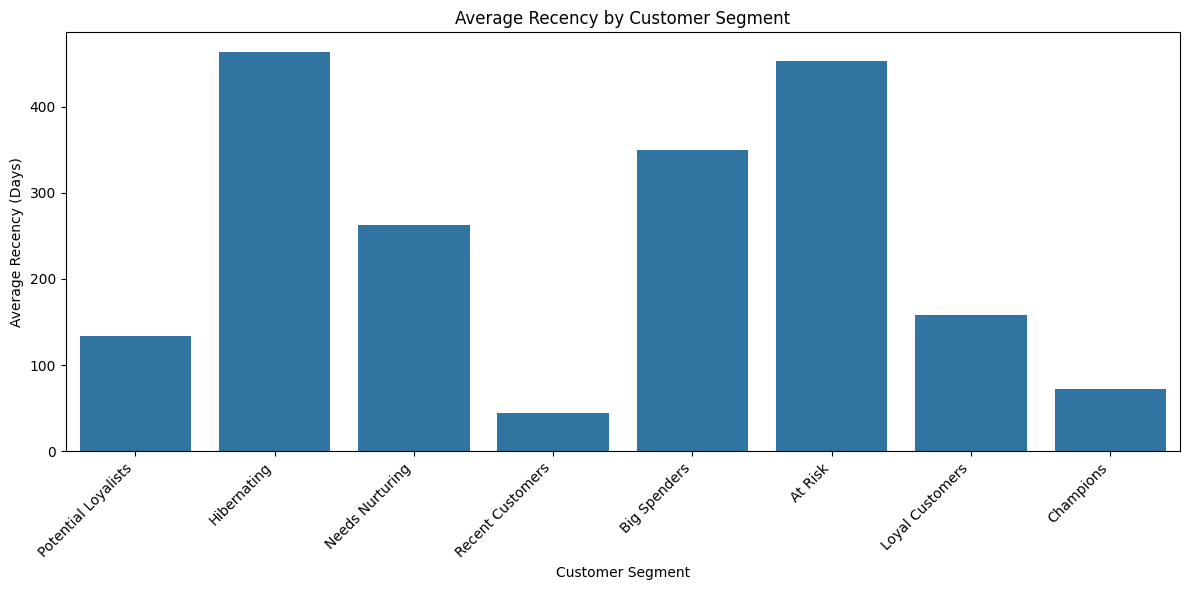

In [13]:
# Average recency by customer segment

plt.figure(figsize=(12, 6))

sns.barplot(
    data=rfm_df,
    x="customer_segment",
    y="recency_days",
    estimator="mean",
    errorbar=None
)

plt.title("Average Recency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Recency (Days)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

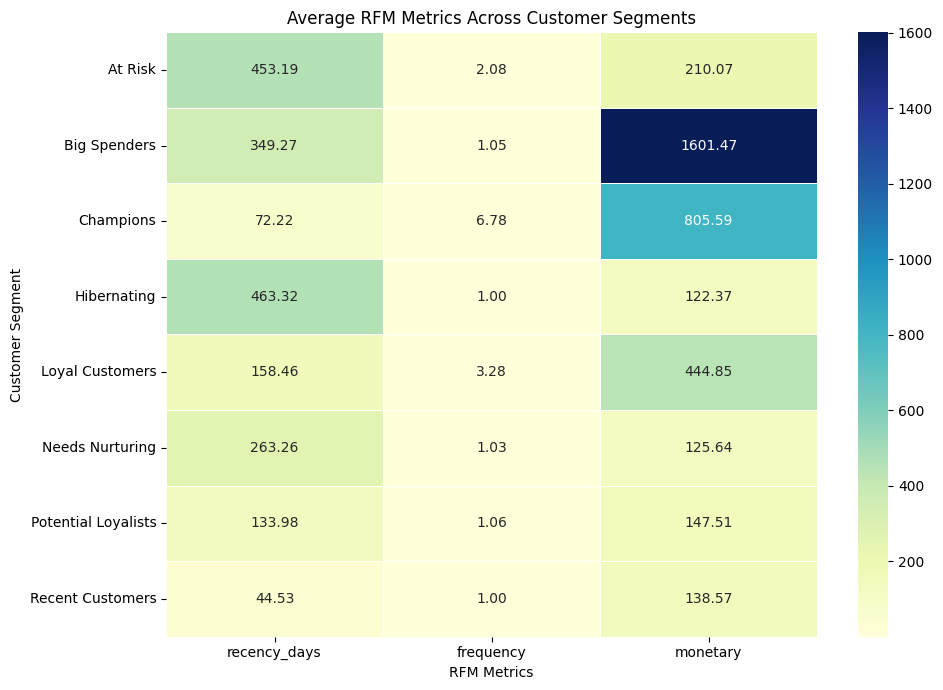

In [14]:
# Average RFM metrics by customer segment

rfm_heatmap = rfm_df.groupby("customer_segment")[
    ["recency_days", "frequency", "monetary"]
].mean()

plt.figure(figsize=(10, 7))

sns.heatmap(
    rfm_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average RFM Metrics Across Customer Segments")
plt.xlabel("RFM Metrics")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

#### Findings: Segment comparison

1. Needs Nurturing is the largest customer segment.
2. Big Spenders have the highest average monetary value.
3. Champions have the highest average purchase frequency.
4. Recent Customers have the lowest average recency.
5. At Risk and Hibernating customers have high recency values,
   suggesting opportunities for targeted re-engagement.

Overall, different customer segments demonstrate different
purchasing behaviours, supporting the use of separate
retention strategies.

## 5. Revenue Contribution by Segment

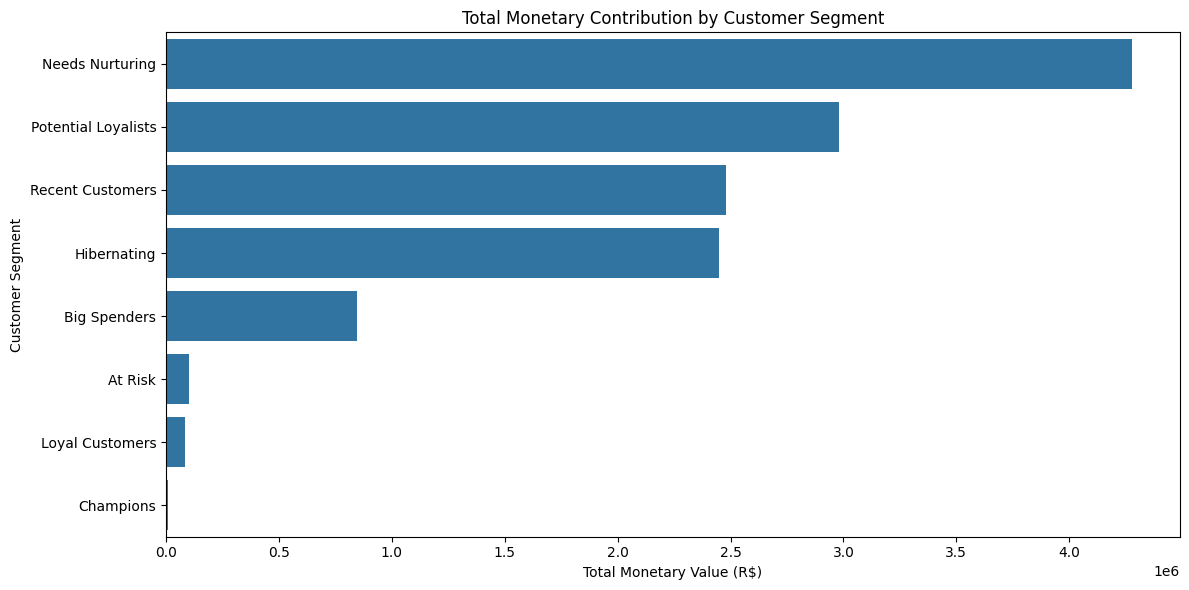

Segment monetary contribution:
customer_segment
Needs Nurturing        4276822.62
Potential Loyalists    2979161.48
Recent Customers       2481046.79
Hibernating            2448458.70
Big Spenders            843972.59
At Risk                 102932.94
Loyal Customers          81852.65
Champions                 7250.34
Name: monetary, dtype: float64


In [15]:
# Total monetary contribution by customer segment

segment_revenue = (
    rfm_df.groupby("customer_segment")["monetary"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_revenue.values,
    y=segment_revenue.index
)

plt.title("Total Monetary Contribution by Customer Segment")
plt.xlabel("Total Monetary Value (R$)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

print("Segment monetary contribution:")
print(segment_revenue.round(2))

In [28]:
# Calculate total monetary contribution by segment

segment_revenue = (
    rfm_df.groupby("customer_segment", observed=True)["monetary"]
    .sum()
    .sort_values(ascending=False)
)

segment_revenue = segment_revenue.reset_index()

segment_revenue.columns = [
    "Customer Segment",
    "Total Monetary Value"
]

# Calculate percentage contribution

total_revenue = segment_revenue["Total Monetary Value"].sum()

segment_revenue["Contribution (%)"] = (
    segment_revenue["Total Monetary Value"] /
    total_revenue * 100
).round(2)

print(segment_revenue.to_string(index=False))

   Customer Segment  Total Monetary Value  Contribution (%)
    Needs Nurturing            4276822.62             32.35
Potential Loyalists            2979161.48             22.53
   Recent Customers            2481046.79             18.77
        Hibernating            2448458.70             18.52
       Big Spenders             843972.59              6.38
            At Risk             102932.94              0.78
    Loyal Customers              81852.65              0.62
          Champions               7250.34              0.05


#### Findings: Monetary contribution

Needs Nurturing contributes the largest share of total
historical customer spending (32.35%), followed by
Potential Loyalists (22.53%).

Big Spenders represent only 0.56% of customers but
contribute 6.38% of total monetary value.

Hibernating customers contribute 18.52%, indicating
that previously valuable customers may be worth
targeting through win-back campaigns.

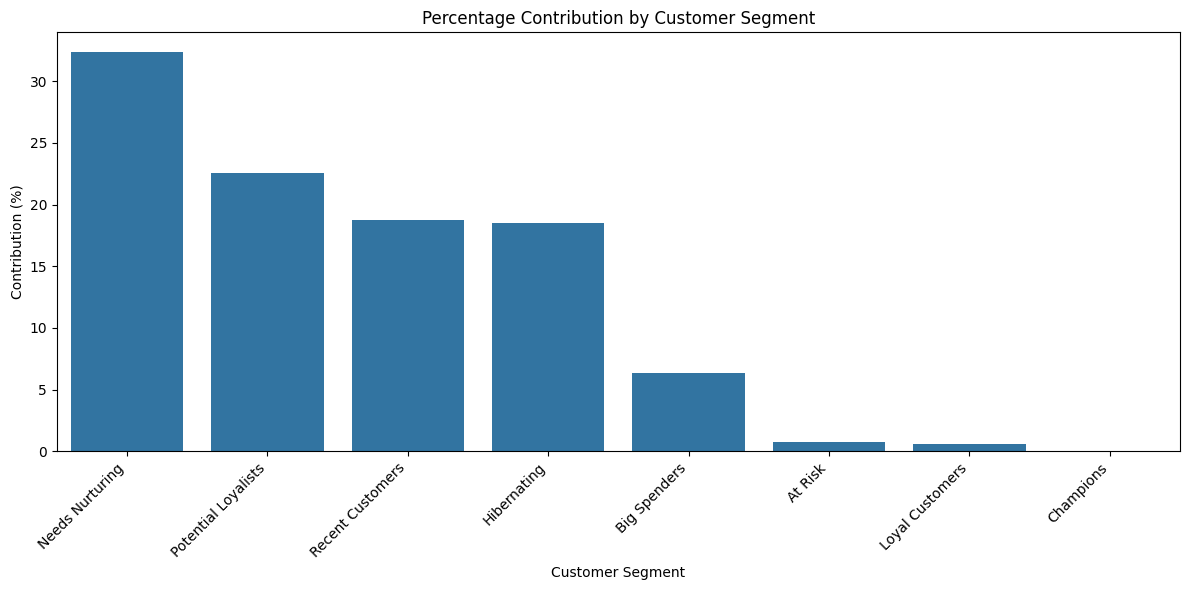

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_revenue,
    x="Customer Segment",
    y="Contribution (%)"
)

plt.title("Percentage Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 6. Relationships Between RFM Metrics
Spearman correlation is used because the distributions are strongly skewed.

              recency_days  frequency  monetary
recency_days         1.000     -0.019    -0.011
frequency           -0.019      1.000     0.146
monetary            -0.011      0.146     1.000


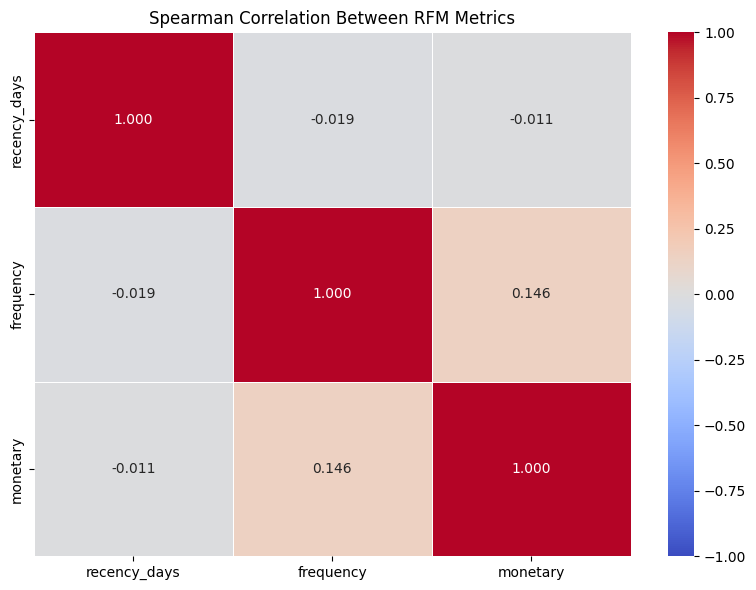

In [16]:
# Calculate Spearman correlation
rfm_correlation = rfm_df[
    ["recency_days", "frequency", "monetary"]
].corr(method="spearman")

print(rfm_correlation.round(3))

# Visualize correlation
plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between RFM Metrics")
plt.tight_layout()
plt.show()

#### Findings: Correlation
All three pairwise correlations are weak. The strongest is frequency–monetary (ρ = 0.146); recency–frequency (ρ = −0.019) and recency–monetary (ρ = −0.011) are close to zero. There is little monotonic relationship between how recently, how often and how much customers buy.

## 7. Purchase Frequency, Recency and Spending Bands
### 7.1 Purchase frequency

In [17]:
# Customer purchase frequency distribution

frequency_distribution = (
    rfm_df["frequency"]
    .value_counts()
    .sort_index()
)

frequency_summary = pd.DataFrame({
    "Order Frequency": frequency_distribution.index,
    "Customer Count": frequency_distribution.values
})

frequency_summary["Percentage"] = (
    frequency_summary["Customer Count"] /
    len(rfm_df) * 100
).round(2)

print(frequency_summary.to_string(index=False))

 Order Frequency  Customer Count  Percentage
               1           90557       97.00
               2            2573        2.76
               3             181        0.19
               4              28        0.03
               5               9        0.01
               6               5        0.01
               7               3        0.00
               9               1        0.00
              15               1        0.00


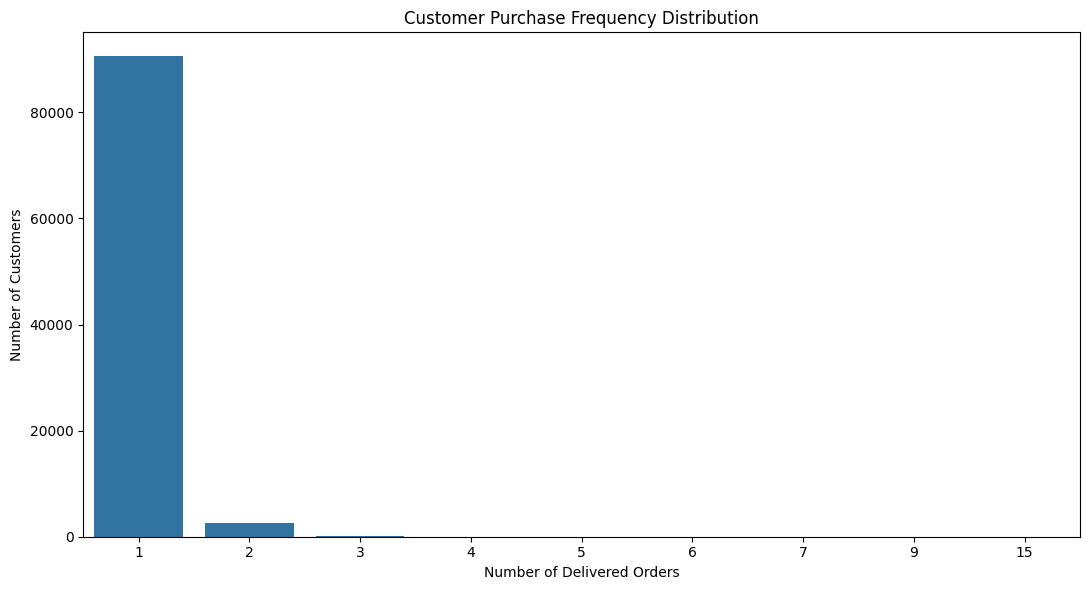

In [18]:
# Purchase frequency distribution chart

plt.figure(figsize=(11, 6))

sns.barplot(
    x=frequency_summary["Order Frequency"],
    y=frequency_summary["Customer Count"]
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Delivered Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

#### Findings: Purchase frequency
**97.00%** of customers (90,557) placed exactly one delivered order. 2.76% placed two, and every higher frequency is below 0.2%; the maximum is 15 orders (a single customer). Repeat purchasing is rare in this dataset.

### 7.2 Recency bands

In [19]:
# Categorize customers based on recency

recency_bins = [0, 90, 180, 365, 550, float("inf")]

recency_labels = [
    "0-90 days",
    "91-180 days",
    "181-365 days",
    "366-550 days",
    "551+ days"
]

rfm_df["recency_group"] = pd.cut(
    rfm_df["recency_days"],
    bins=[-1, 90, 180, 365, 550, float("inf")],
    labels=recency_labels
)

# Calculate customer distribution
recency_summary = rfm_df["recency_group"].value_counts().reindex(
    recency_labels
).reset_index()

recency_summary.columns = ["Recency Group", "Customer Count"]

recency_summary["Percentage"] = (
    recency_summary["Customer Count"] /
    len(rfm_df) * 100
).round(2)

print(recency_summary.to_string(index=False))

Recency Group  Customer Count  Percentage
    0-90 days           18520       19.84
  91-180 days           19706       21.11
 181-365 days           34452       36.90
 366-550 days           18326       19.63
    551+ days            2354        2.52


#### Findings: Recency analysis
The largest customer group (36.90%) made its last observed
purchase 181–365 days before the dataset reference date.
Approximately 22.15% of customers had a recency greater
than 365 days, suggesting a potential audience for
targeted re-engagement campaigns.

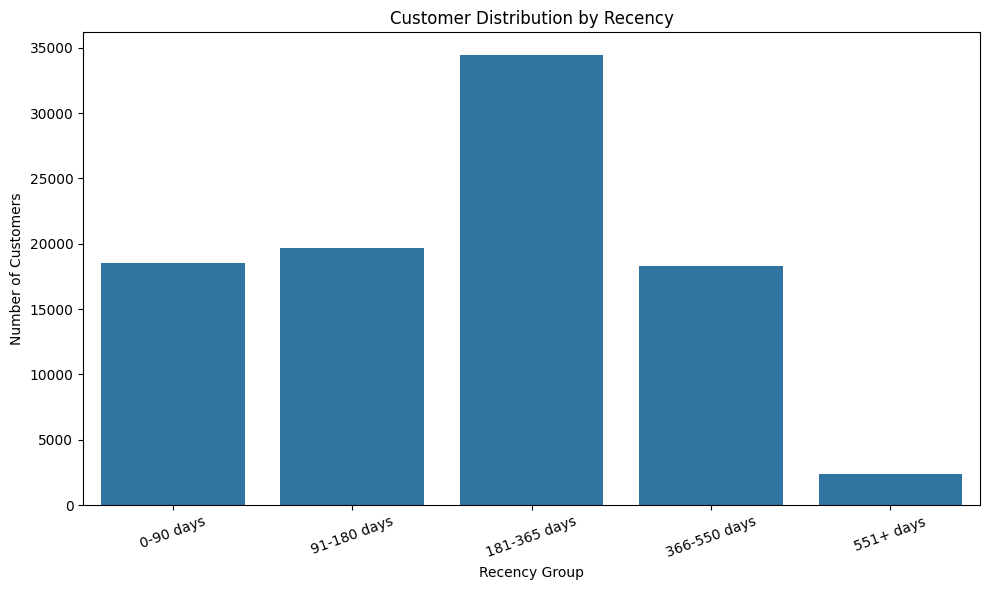

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=recency_summary,
    x="Recency Group",
    y="Customer Count"
)

plt.title("Customer Distribution by Recency")
plt.xlabel("Recency Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 7.3 Spending bands

In [21]:
# Categorize customers by monetary value

monetary_bins = [0, 100, 300, 500, 1000, float("inf")]

monetary_labels = [
    "Below R$100",
    "R$100-299",
    "R$300-499",
    "R$500-999",
    "R$1000+"
]

rfm_df["monetary_group"] = pd.cut(
    rfm_df["monetary"],
    bins=monetary_bins,
    labels=monetary_labels,
    right=False
)

# Calculate spending distribution

monetary_summary = (
    rfm_df["monetary_group"]
    .value_counts()
    .reindex(monetary_labels)
    .reset_index()
)

monetary_summary.columns = [
    "Monetary Group",
    "Customer Count"
]

monetary_summary["Percentage"] = (
    monetary_summary["Customer Count"] /
    len(rfm_df) * 100
).round(2)

print(monetary_summary.to_string(index=False))

Monetary Group  Customer Count  Percentage
   Below R$100           53466       57.27
     R$100-299           31817       34.08
     R$300-499            4441        4.76
     R$500-999            2693        2.88
       R$1000+             941        1.01


#### Findings: Monetary analysis
Approximately 91.35% of customers generated less than
R$300 in observed product spending. Only 3.89% spent
R$500 or more, indicating that high-spending customers
represent a relatively small portion of the customer base.

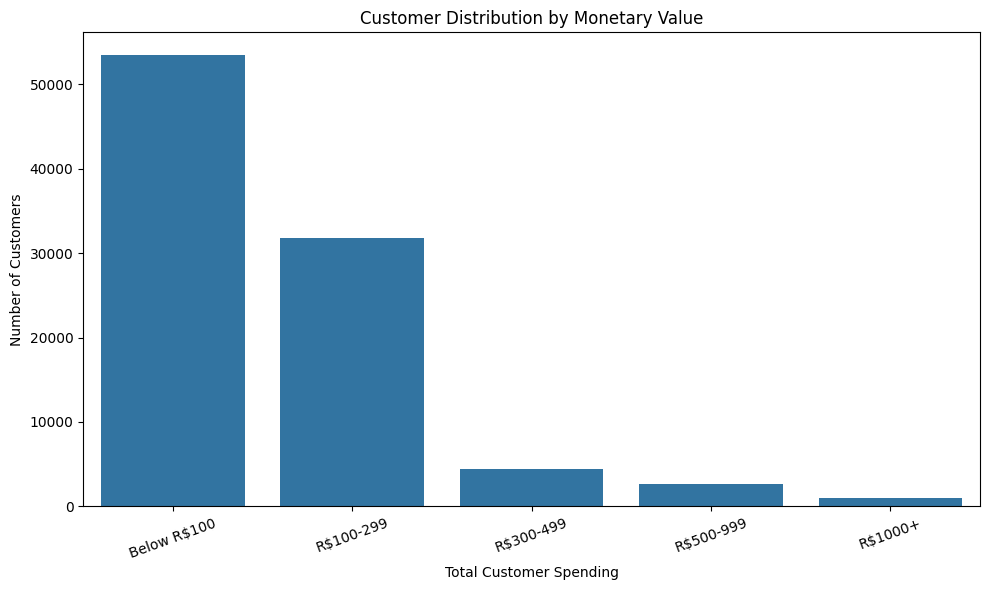

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=monetary_summary,
    x="Monetary Group",
    y="Customer Count"
)

plt.title("Customer Distribution by Monetary Value")
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## 8. RFM Score Validation by Segment

In [31]:
# RFM score distribution by customer segment

rfm_score_summary = (
    rfm_df.groupby("customer_segment", observed=True)
    .agg(
        avg_R_score=("R_score", "mean"),
        avg_F_score=("F_score", "mean"),
        avg_M_score=("M_score", "mean"),
        avg_RFM_total=("RFM_total", "mean")
    )
    .round(2)
)

print(rfm_score_summary)

                     avg_R_score  avg_F_score  avg_M_score  avg_RFM_total
customer_segment                                                         
At Risk                     1.90         2.07         2.02           6.00
Big Spenders                2.61         1.05         5.00           8.66
Champions                   4.67         4.33         4.11          13.11
Hibernating                 1.89         1.00         1.49           4.38
Loyal Customers             3.92         3.06         2.85           9.83
Needs Nurturing             3.00         1.03         1.52           5.55
Potential Loyalists         4.03         1.06         1.60           6.69
Recent Customers            5.00         1.00         1.55           7.55


#### Findings: RFM score validation

Champions achieved the highest average RFM total score
(13.11), reflecting strong performance across all
three dimensions.

Big Spenders achieved an average monetary score of 5.00,
while Recent Customers achieved an average recency score
of 5.00.

The findings demonstrate that different segments have
distinct purchasing characteristics and require
different retention strategies.

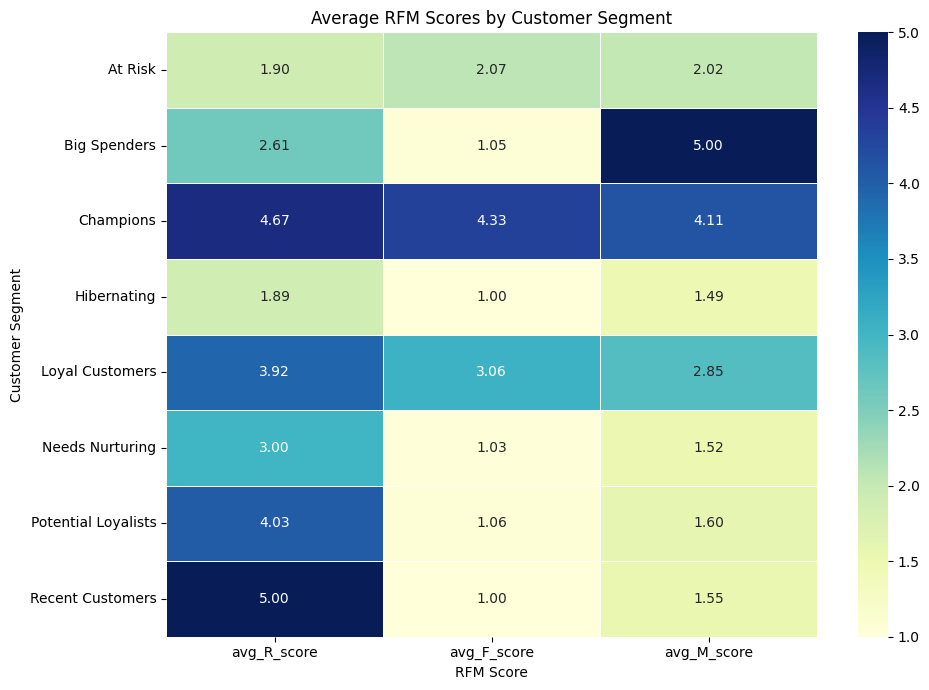

In [32]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    rfm_score_summary[
        ["avg_R_score", "avg_F_score", "avg_M_score"]
    ],
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    vmin=1,
    vmax=5
)

plt.title("Average RFM Scores by Customer Segment")
plt.xlabel("RFM Score")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()


## 9. Final EDA Validation
Confirms the dataset is complete and consistent after the added recency and monetary groupings.

In [33]:
# Final EDA validation

print("Dataset Shape:", rfm_df.shape)

print("\nMissing Values:")
print(rfm_df.isnull().sum())

print("\nDuplicate Customer IDs:")
print(rfm_df["customer_unique_id"].duplicated().sum())

print("\nRFM Score Range:")
print("R Score:", rfm_df["R_score"].min(), "-", rfm_df["R_score"].max())
print("F Score:", rfm_df["F_score"].min(), "-", rfm_df["F_score"].max())
print("M Score:", rfm_df["M_score"].min(), "-", rfm_df["M_score"].max())

print("\nInvalid RFM Scores:")
print(
    ((rfm_df[["R_score", "F_score", "M_score"]] < 1) |
     (rfm_df[["R_score", "F_score", "M_score"]] > 5))
    .any(axis=1).sum()
)

print("\nCustomer Segment Count:")
print(rfm_df["customer_segment"].nunique())

print("\nTotal Customers:")
print(rfm_df["customer_unique_id"].nunique())

Dataset Shape: (93358, 12)

Missing Values:
customer_unique_id    0
recency_days          0
frequency             0
monetary              0
R_score               0
F_score               0
M_score               0
RFM_score             0
RFM_total             0
customer_segment      0
recency_group         0
monetary_group        0
dtype: int64

Duplicate Customer IDs:
0

RFM Score Range:
R Score: 1 - 5
F Score: 1 - 5
M Score: 1 - 5

Invalid RFM Scores:
0

Customer Segment Count:
8

Total Customers:
93358


#### Findings: Validation
12 columns (the 10 original plus `recency_group` and `monetary_group`), 93,358 unique customers, no missing values, no duplicate customer IDs, no invalid RFM scores and 8 customer segments.

## Key Takeaways
1. **Most customers buy once:** 97.00% have a single delivered order, so retention and repeat purchasing are the core opportunity.
2. **Spending is highly skewed:** a median of R$89.73 versus a mean of R$141.62; 91.35% of customers spent less than R$300.
3. **A tiny group carries outsized value:** *Big Spenders* are 0.56% of customers but 6.38% of spending.
4. **Dormant customers are a sizeable pool:** *Hibernating* customers (21.43% of customers) contribute 18.52% of spending, and 22.15% of all customers last bought more than 365 days before the reference date.
5. **Segments behave differently:** their RFM profiles are distinct, which supports separate retention strategies. Notebook 04 tests this with unsupervised K-Means clustering.